In [1]:
from math import sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import test_proportions_2indep

rng = np.random.default_rng(7)

## Задание 1

In [2]:
gen_set_mean = 120
n = 100
selection_mean = 124
gen_set_sigma = 25

# H0 - среднее время на карточке вакансии по генеральной совокупности равно 120 секунд

# Считаем z-статистику
se = gen_set_sigma / (sqrt(n))
z = (selection_mean - gen_set_mean) / se
print(f"z-статистика: {round(z, 5)}")

# a = 0.05, критические значения +-1.96
if -1.96 <= z <= 1.96:
    print(f"Значение статистики не попадает в критическую область. H0 не отвергается")
else:
    print(f"Значение статистики попадает в критическую область. H0 отвергается")

z-статистика: 1.6
Значение статистики не попадает в критическую область. H0 не отвергается


Ответ: оснований отвергать H0 нет, так как она не попадает в критическую область.

## Задание 2

In [3]:
n1 = 40
mu1 = 50
s1 = 10
se1 = s1 / sqrt(n1)

n2 = 40
mu2 = 55
s2 = 10
se2 = s2 / sqrt(n2)

diff_mu = mu2 - mu1
print(f"Разница средних по выборкам: {diff_mu}")

# Стандартная ошибка разницы
diff_se = sqrt(se1**2 + se2**2)

# t = stats.ttest_ind_from_stats(mu2, s2, n2, mu1, s1, n1, equal_var=False)

# Количество степеней свободы Уэлча
# df = t.df
df = (se1**2 + se2**2)**2 / (se1**4 / (n1-1) + (se2**4 / (n2-1)))

# Критическое значение
t_crit = stats.t.ppf(0.975, df)
# conf_int = t.confidence_interval(0.95)
# upper = conf_int.high
# lower = conf_int.low
upper = diff_mu + t_crit * diff_se
low = diff_mu - t_crit * diff_se

print(f"Границы интервала: {round(low, 5)} --- {round(upper, 5)}")

Разница средних по выборкам: 5
Границы интервала: 0.54833 --- 9.45167


- 0 не попадает в интервал, поэтому H0 отвергается -> данные плохо согласуются с отсутсвием разницы
- Самый маленький эффект, согласующийся с данными, - левая граница (~0.55с)

## Задание 3

In [4]:
resp1 = 90
n1 = 1000
conv1 = resp1 / n1
print(f"Конверсия первой группы: {conv1}")

resp2 = 120
n2 = 1000
conv2 = resp2 / n2
print(f"Конверсия второй группы: {conv2}")

print(f"H0 - конверсии генеральных совокупностей для выборок совпадают")

conv_diff = (conv2 - conv1) * 100
print(f"Разница конверсий: {conv_diff} п.п.")

# Считаем z-статистику для долей
# p = (resp1 + resp2) / (n1 + n2)
# z = (conv2 - conv1) / sqrt((p) * (1 - p) * (1 / n2 + 1 / n1))

z = test_proportions_2indep(
    resp1, n1,
    resp2, n2,
    compare="diff", method="score"
)
print(f"Значение статистики: {round(z.statistic, 5)}")

# Берем a = 0.05
upper = stats.norm.ppf(0.975)
lower = -upper

if lower <= z.statistic <= upper:
    print(f"Значение статистики не попадает в критическую область. H0 не отвергается")
else:
    print(f"Значение статистики попадает в критическую область. H0 отвергается")

Конверсия первой группы: 0.09
Конверсия второй группы: 0.12
H0 - конверсии генеральных совокупностей для выборок совпадают
Разница конверсий: 3.0 п.п.
Значение статистики: -2.18772
Значение статистики попадает в критическую область. H0 отвергается


- Основание отвергать H0 - есть: значение статистики попало в критическую область

## Задание 4

In [5]:
n = 2000

pvalue_data = []

for _ in range(n):
    a = rng.normal(0, 1, 200)
    b = rng.normal(0, 1, 200)
    ttest = stats.ttest_ind(a, b, equal_var=False)
    pvalue_data.append(ttest.pvalue)

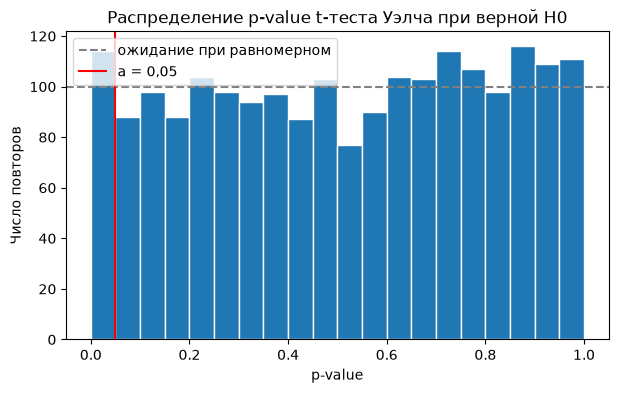

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))

bins = 20
ax.hist(pvalue_data, bins=bins, range=(0, 1), edgecolor="white")
ax.axhline(n / bins, color="gray", linestyle="--", label="ожидание при равномерном")
ax.axvline(0.05, color="red", label="a = 0,05")

ax.set_title("Распределение p-value t-теста Уэлча при верной H0")
ax.set_xlabel("p-value")
ax.set_ylabel("Число повторов")
ax.legend()

plt.show()


- Распределение p-value равномерное: столбики примерно одной высоты, отличия между ними — случайный шум.
- Причина: p-value — площадь хвоста за наблюдённым t, поэтому при верной H0 доля p-value меньше любого порога a равна самому a. Здесь H0 верна по построению, так что каждое p-value меньше a — ложная тревога, и тест делает их с частотой a.

## Задание 5

In [7]:
n = 1000

data = []

for _ in range(n):
    a = rng.normal(0, 1, 60)
    b = rng.normal(1, 1, 60)
    b[0] = -50
    b[-1] = -50
    diff_mu = np.mean(b) - np.mean(a)
    ttest = stats.ttest_ind(b, a, equal_var=False)
    manwhitney = stats.mannwhitneyu(a, b, alternative="two-sided")
    data.append([diff_mu, ttest.statistic, ttest.pvalue, manwhitney.statistic, manwhitney.pvalue])

data = np.array(data)

print(f"Средняя разница средних (вторая минус первая): {data[:, 0].mean():.3f}")
print(f"Доля повторов, где разница меньше 0: {(data[:, 0] < 0).mean():.1%}")

Средняя разница средних (вторая минус первая): -0.697
Доля повторов, где разница меньше 0: 100.0%


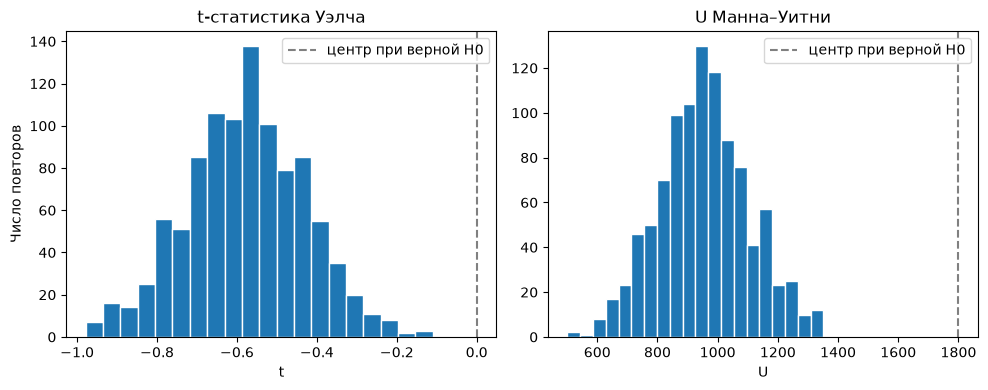

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(data[:, 1], bins=20, edgecolor="white")
axes[0].axvline(0, color="gray", linestyle="--", label="центр при верной H0")
axes[0].set_title("t-статистика Уэлча")
axes[0].set_xlabel("t")
axes[0].set_ylabel("Число повторов")
axes[0].legend()

axes[1].hist(data[:, 3], bins=20, edgecolor="white")
axes[1].axvline(60 * 60 / 2, color="gray", linestyle="--", label="центр при верной H0")
axes[1].set_title("U Манна–Уитни")
axes[1].set_xlabel("U")
axes[1].legend()

plt.tight_layout()
plt.show()


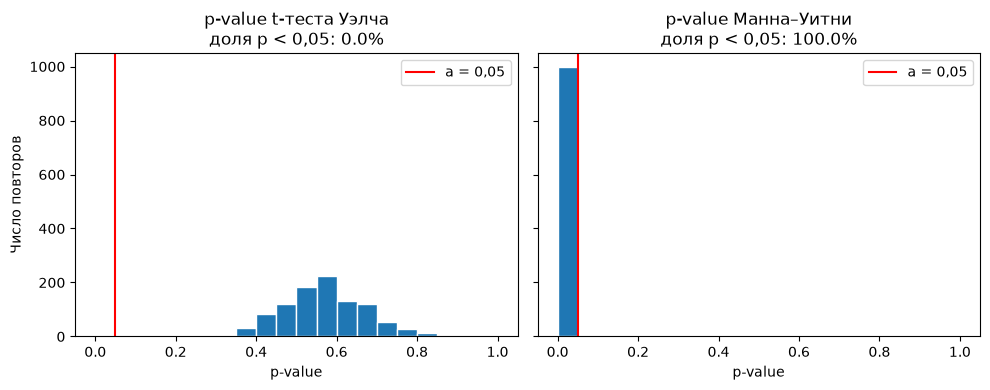

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, col, title in [
    (axes[0], 2, "p-value t-теста Уэлча"),
    (axes[1], 4, "p-value Манна–Уитни"),
]:
    share = (data[:, col] < 0.05).mean()
    ax.hist(data[:, col], bins=20, range=(0, 1), edgecolor="white")
    ax.axvline(0.05, color="red", label="a = 0,05")
    ax.set_title(f"{title}\nдоля p < 0,05: {share:.1%}")
    ax.set_xlabel("p-value")
    ax.legend()

axes[0].set_ylabel("Число повторов")
plt.tight_layout()
plt.show()


- Выводы разошлись: t-тест Уэлча не отвергает H0 ни в одном повторе, Манна–Уитни отвергает во всех.
- Два значения −50 перевешивают сдвиг +1 у остальных наблюдений второй группы: разница средних меняет знак, а дисперсия раздувается, поэтому t остаётся маленьким и сдвига не видно.
- Манна–Уитни работает с рангами: для него −50 — просто два самых малых наблюдения, поэтому сдвиг основной массы виден.

## Задание 6

In [10]:
a = rng.normal(10, 2, 80)
b = rng.normal(10.8, 2.6, 75)

# H0 - средние генеральных совокупностей совпадают, разница равна 0
diff_mu = b.mean() - a.mean()
print(f"Разница средних (вторая минус первая): {round(diff_mu, 5)}")

ttest = stats.ttest_ind(b, a, equal_var=False)
print(f"p-value: {round(ttest.pvalue, 5)}")

conf_int = ttest.confidence_interval(0.95)
print(f"Границы интервала: {round(conf_int.low, 5)} --- {round(conf_int.high, 5)}")

# Берем a = 0.05
if ttest.pvalue < 0.05:
    print(f"p-value меньше 0.05. H0 отвергается")
else:
    print(f"p-value не меньше 0.05. H0 не отвергается")

Разница средних (вторая минус первая): 1.02935
p-value: 0.00676
Границы интервала: 0.28879 --- 1.76991
p-value меньше 0.05. H0 отвергается


- 0 не попадает в интервал, а p-value меньше порога, поэтому H0 отвергается -> данные плохо согласуются с отсутствием разницы
- Самый маленький эффект, согласующийся с данными, - левая граница интервала: это положительный, но небольшой эффект

## Задание 7

In [11]:
n = 2000

boot_diffs = []

for _ in range(n):
    a_boot = rng.choice(a, size=len(a), replace=True)
    b_boot = rng.choice(b, size=len(b), replace=True)
    boot_diffs.append(b_boot.mean() - a_boot.mean())

boot_diffs = np.array(boot_diffs)

# Границы, отсекающие по 2.5% значений с каждого края
boot_low, boot_upper = np.percentile(boot_diffs, [2.5, 97.5])
print(f"Границы бутстрап-интервала: {round(boot_low, 5)} --- {round(boot_upper, 5)}")
print(f"Границы интервала Уэлча: {round(conf_int.low, 5)} --- {round(conf_int.high, 5)}")

share_le_zero = (boot_diffs <= 0).mean()
print(f"Доля повторных выборок с разницей не больше 0: {share_le_zero}")

Границы бутстрап-интервала: 0.28802 --- 1.75764
Границы интервала Уэлча: 0.28879 --- 1.76991
Доля повторных выборок с разницей не больше 0: 0.0025


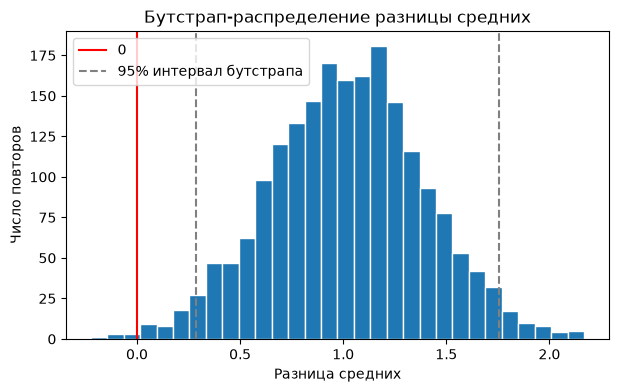

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(boot_diffs, bins=30, edgecolor="white")
ax.axvline(0, color="red", label="0")
ax.axvline(boot_low, color="gray", linestyle="--", label="95% интервал бутстрапа")
ax.axvline(boot_upper, color="gray", linestyle="--")

ax.set_title("Бутстрап-распределение разницы средних")
ax.set_xlabel("Разница средних")
ax.set_ylabel("Число повторов")
ax.legend()

plt.show()

- Границы бутстрапа почти совпали с интервалом Уэлча: при таких размерах выборок разница средних распределена близко к нормальному, и оба способа оценивают один и тот же разброс этой разницы - один по формуле стандартной ошибки, другой перебором выборок
- Эту долю нельзя назвать p-value: бутстрап-распределение строится вокруг наблюдённой разницы, а не вокруг 0, то есть без допущения, что H0 верна. Доля показывает, как часто повторные выборки дают разницу противоположного знака, - это оценка неопределённости эффекта, а не вероятность увидеть такой результат при верной H0. Она ещё и односторонняя, а p-value здесь двустороннее